# ANN 1: Regularization

We train the same network 5 times and only change the regularization:

1. No regularization
2. L2
3. Dropout
4. BatchNorm
5. All together + Early Stopping

# Step 1: Setup

In [1]:
import os

# clone the team repo (Colab only)
if not os.path.exists("src"):
    !git clone https://github.com/sara-alsalmi/customer-churn-prediction.git
    %cd customer-churn-prediction

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score

from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

from src.preprocess import get_data, get_class_weights
from src.evaluate import evaluate_scores

keras.utils.set_random_seed(42)
os.makedirs("results/ann1", exist_ok=True)
os.makedirs("models", exist_ok=True)

# Step 2: Load the Data

In [3]:
d = get_data()

X_train, y_train = d["X_train"], d["y_train"]
X_val, y_val = d["X_val"], d["y_val"]
X_test, y_test = d["X_test"], d["y_test"]

print(X_train.shape, X_val.shape, X_test.shape)

(28822, 63) (6176, 63) (6178, 63)


Only 11% are yes, so we use class weights.

In [4]:
class_weight = get_class_weights(y_train)
print(class_weight)

{0: 0.5638327008098908, 1: 4.416487894575544}


# Step 3: Build the Model

Dense(128) -> Dense(64) -> Dense(1)

In [5]:
def build_model(l2_value=0, dropout=0, batch_norm=False):
    model = Sequential()
    model.add(Input(shape=(X_train.shape[1],)))

    for units in [128, 64]:
        model.add(Dense(units, activation="relu", kernel_regularizer=l2(l2_value)))
        if batch_norm:
            model.add(BatchNormalization())
        if dropout > 0:
            model.add(Dropout(dropout))

    model.add(Dense(1, activation="sigmoid"))
    model.compile(optimizer="adam", loss="binary_crossentropy")
    return model

# Step 4: Train the 5 Models

60 epochs, batch size 512. Only the last model uses Early Stopping.

In [6]:
experiments = {
    "No regularization": dict(),
    "L2": dict(l2_value=0.001),
    "Dropout": dict(dropout=0.3),
    "BatchNorm": dict(batch_norm=True),
    "All + Early Stopping": dict(l2_value=0.001, dropout=0.3, batch_norm=True),
}

early_stop = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)

models = {}
histories = {}

for name, params in experiments.items():
    model = build_model(**params)
    callbacks = [early_stop] if name == "All + Early Stopping" else []

    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=60, batch_size=512, class_weight=class_weight,
                        callbacks=callbacks, verbose=0)

    models[name] = model
    histories[name] = history
    print(name, "done")

No regularization done


L2 done


Dropout done


BatchNorm done


All + Early Stopping done


# Step 5: Learning Curves

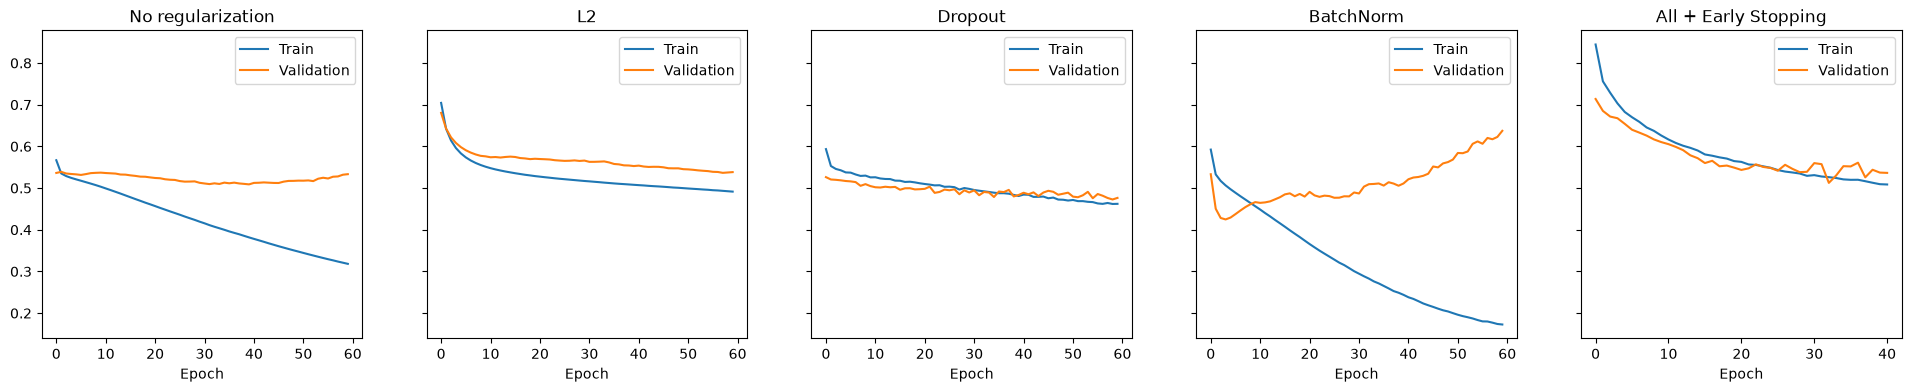

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(24, 4), sharey=True)

for ax, name in zip(axes, histories):
    ax.plot(histories[name].history["loss"], label="Train")
    ax.plot(histories[name].history["val_loss"], label="Validation")
    ax.set_title(name)
    ax.set_xlabel("Epoch")
    ax.legend()

plt.savefig("results/ann1/learning_curves.png", bbox_inches="tight")
plt.show()

- **No regularization:** train loss keeps going down, validation loss goes up after about epoch 30. Overfitting.
- **L2** and **Dropout:** train and validation stay close. Less overfitting.
- **BatchNorm alone:** the worst. Validation loss goes up a lot after epoch 5.
- **All + Early Stopping:** lines stay close, and training stopped at epoch 41.

# Step 6: Compare

- `val_pr_auc`: higher is better
- `gap`: validation loss minus train loss. Big gap = overfitting

In [8]:
rows = []
for name in models:
    val_scores = models[name].predict(X_val, verbose=0).ravel()
    h = histories[name].history
    rows.append({"model": name,
                 "epochs": len(h["loss"]),
                 "val_pr_auc": average_precision_score(y_val, val_scores),
                 "gap": h["val_loss"][-1] - h["loss"][-1]})

comparison = pd.DataFrame(rows).round(3)
comparison.to_csv("results/ann1/comparison.csv", index=False)
comparison

,model,epochs,val_pr_auc,gap
0,No regularization,60,0.408,0.215
1,L2,60,0.454,0.047
2,Dropout,60,0.449,0.014
3,BatchNorm,60,0.371,0.465
4,All + Early Stopping,41,0.472,0.028


All + Early Stopping is the best (0.472). L2 and Dropout are both better than no regularization (0.408). BatchNorm alone is the worst (0.371) because it overfits the most.

# Step 7: Team Evaluation

In [9]:
best_name = comparison.sort_values("val_pr_auc").iloc[-1]["model"]
best_model = models[best_name]
print("Best model:", best_name)

val_scores = best_model.predict(X_val, verbose=0).ravel()
test_scores = best_model.predict(X_test, verbose=0).ravel()

metrics = evaluate_scores("ann1_regularization", d["id_val"], y_val, val_scores,
                          d["id_test"], y_test, test_scores)
pd.Series(metrics).round(3)

Best model: All + Early Stopping


val_avg_precision     0.472
test_avg_precision    0.430
test_roc_auc          0.766
test_precision        0.423
test_recall           0.539
test_f1               0.474
threshold             0.708
dtype: float64

Test PR-AUC is 0.43 and ROC-AUC is 0.77. It finds 54% of the yes customers (recall).

# Step 8: Save and Load

In [10]:
best_model.save("models/ann1_regularization.keras")

loaded_model = keras.models.load_model("models/ann1_regularization.keras")
print("Same predictions:", np.allclose(val_scores, loaded_model.predict(X_val, verbose=0).ravel(), atol=1e-5))

Same predictions: True


# Summary

- Without regularization the model overfits.
- L2 and Dropout reduce overfitting and improve PR-AUC.
- BatchNorm alone makes it worse, it only helps together with L2 and Dropout.
- Best model: L2 + Dropout + BatchNorm + Early Stopping. PR-AUC went up from 0.41 to 0.47 on validation (0.43 on test).